In [1]:
 #Final Project: Analysis of Birth Outcomes by Michigan City (2014)
# Student: Osman Yildiz
# Course: IT 540

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, classification_report
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
# PART A: STATING AND REFINING THE QUESTION
##############################################################################
"""
RESEARCH QUESTION:
Can we predict inadequate prenatal care rates in Michigan cities based on 
demographic characteristics and other birth outcome indicators?

REFINED QUESTION:
1. What demographic factors (race/ethnicity distributions) are most strongly 
   associated with inadequate prenatal care?
2. Can we identify clusters of cities with similar birth outcome profiles?
3. Can we build a predictive model for inadequate prenatal care rates?

QUESTION TYPE: This is primarily a PREDICTIVE question with elements of 
EXPLORATORY and INFERENTIAL analysis.
"""

'\nRESEARCH QUESTION:\nCan we predict inadequate prenatal care rates in Michigan cities based on \ndemographic characteristics and other birth outcome indicators?\n\nREFINED QUESTION:\n1. What demographic factors (race/ethnicity distributions) are most strongly \n   associated with inadequate prenatal care?\n2. Can we identify clusters of cities with similar birth outcome profiles?\n3. Can we build a predictive model for inadequate prenatal care rates?\n\nQUESTION TYPE: This is primarily a PREDICTIVE question with elements of \nEXPLORATORY and INFERENTIAL analysis.\n'

In [3]:
##############################################################################
# PART B: EXPLORING THE DATA
##############################################################################

print("="*80)
print("PART B: DATA EXPLORATION")
print("="*80)

# Load the data
birth_data = pd.read_csv('Births_byCity_2014.csv')
display(birth_data)

print(f"\nDataset shape: {birth_data.shape}")
print(f"Number of cities: {len(birth_data)}")

# Display first few rows
print("\nFirst 5 rows of data:")
print(birth_data.head())

# Check for missing values
print("\nMissing values per column:")
print(birth_data.isnull().sum())

# Basic statistics
print("\nBasic statistics:")
print(birth_data.describe())

# Create calculated features
# Calculate percentages for demographic groups
birth_data['PctNonHispWhite'] = (birth_data['NonHispWhite'] / birth_data['TotalBirths'] * 100).fillna(0)
birth_data['PctNonHispBlack'] = (birth_data['NonHispBlack'] / birth_data['TotalBirths'] * 100).fillna(0)
birth_data['PctHispanic'] = (birth_data['Hispanic'] / birth_data['TotalBirths'] * 100).fillna(0)
birth_data['PctInadequatePrenatal'] = (birth_data['InadequatePrenatal'] / birth_data['TotalBirths'] * 100).fillna(0)
birth_data['PctLowBirthWeight'] = (birth_data['LowBirthWeight'] / birth_data['TotalBirths'] * 100).fillna(0)
birth_data['PctTeenMothers'] = (birth_data['TeenMothers'] / birth_data['TotalBirths'] * 100).fillna(0)

# Filter to cities with at least 50 births for statistical validity
birth_data_filtered = birth_data[birth_data['TotalBirths'] >= 50].copy()
print(f"\nCities with 50+ births: {len(birth_data_filtered)}")







PART B: DATA EXPLORATION


,OBJECTID,GeoID10_1,CityName,CountyName,TotalBirths,NonHispWhite,NonHispBlack,NonHIspOther,Hispanic,InadequatePrenatal,LowBirthWeight,TeenMothers,Shape__Area,Shape__Length
0,1,2.615788e+09,Wisner township,Tuscola County,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,7.159291e+08,122150.757761
1,2,2.615785e+09,Wells township,Tuscola County,24.0,21.0,NaN,NaN,NaN,9.0,NaN,NaN,9.890882e+08,125836.688279
2,3,2.615784e+09,Watertown township,Tuscola County,21.0,20.0,NaN,NaN,NaN,8.0,NaN,NaN,9.182624e+08,121585.123445
3,4,2.615703e+09,Arbela township,Tuscola County,33.0,32.0,NaN,NaN,NaN,9.0,NaN,NaN,9.338147e+08,122160.464291
4,5,2.615702e+09,Almer township,Tuscola County,32.0,27.0,NaN,NaN,NaN,12.0,NaN,NaN,9.571293e+08,124752.392151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1528,1529,2.603724e+09,East Lansing city,Clinton County,26.0,17.0,NaN,7.0,NaN,6.0,NaN,NaN,9.934412e+07,86952.346521
1529,1530,2.601570e+09,Rutland charter township,Barry County,47.0,42.0,NaN,NaN,NaN,15.0,NaN,NaN,1.007246e+09,130576.041408
1530,1531,2.601566e+09,Prairieville township,Barry County,29.0,29.0,NaN,NaN,NaN,11.0,NaN,NaN,1.017014e+09,127780.781185
1531,1532,2.601561e+09,Orangeville township,Barry County,33.0,33.0,NaN,NaN,NaN,8.0,NaN,NaN,9.939767e+08,126139.285447



Dataset shape: (1533, 14)
Number of cities: 1533

First 5 rows of data:
   OBJECTID     GeoID10_1            CityName      CountyName  TotalBirths  \
0         1  2.615788e+09     Wisner township  Tuscola County          8.0   
1         2  2.615785e+09      Wells township  Tuscola County         24.0   
2         3  2.615784e+09  Watertown township  Tuscola County         21.0   
3         4  2.615703e+09     Arbela township  Tuscola County         33.0   
4         5  2.615702e+09      Almer township  Tuscola County         32.0   

   NonHispWhite  NonHispBlack  NonHIspOther  Hispanic  InadequatePrenatal  \
0           8.0           NaN           NaN       NaN                 NaN   
1          21.0           NaN           NaN       NaN                 9.0   
2          20.0           NaN           NaN       NaN                 8.0   
3          32.0           NaN           NaN       NaN                 9.0   
4          27.0           NaN           NaN       NaN                12.0

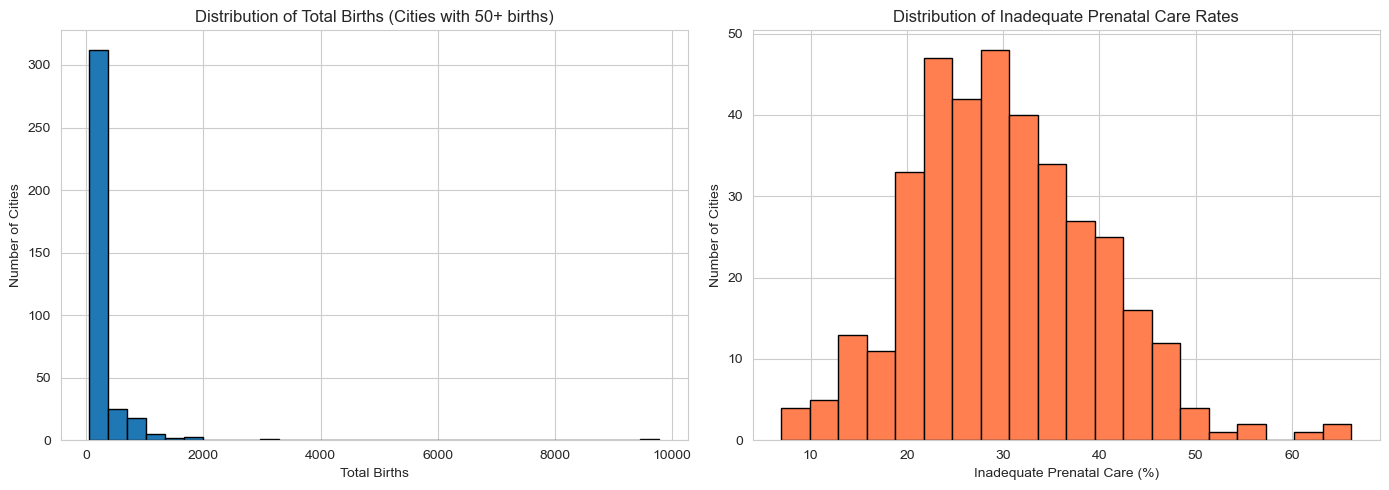

In [4]:

# VISUALIZATION 1: Distribution of Total Births
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.hist(birth_data_filtered['TotalBirths'], bins=30, edgecolor='black')
plt.xlabel('Total Births')
plt.ylabel('Number of Cities')
plt.title('Distribution of Total Births (Cities with 50+ births)')

plt.subplot(1, 2, 2)
plt.hist(birth_data_filtered['PctInadequatePrenatal'], bins=20, edgecolor='black', color='coral')
plt.xlabel('Inadequate Prenatal Care (%)')
plt.ylabel('Number of Cities')
plt.title('Distribution of Inadequate Prenatal Care Rates')
plt.tight_layout()
plt.show()

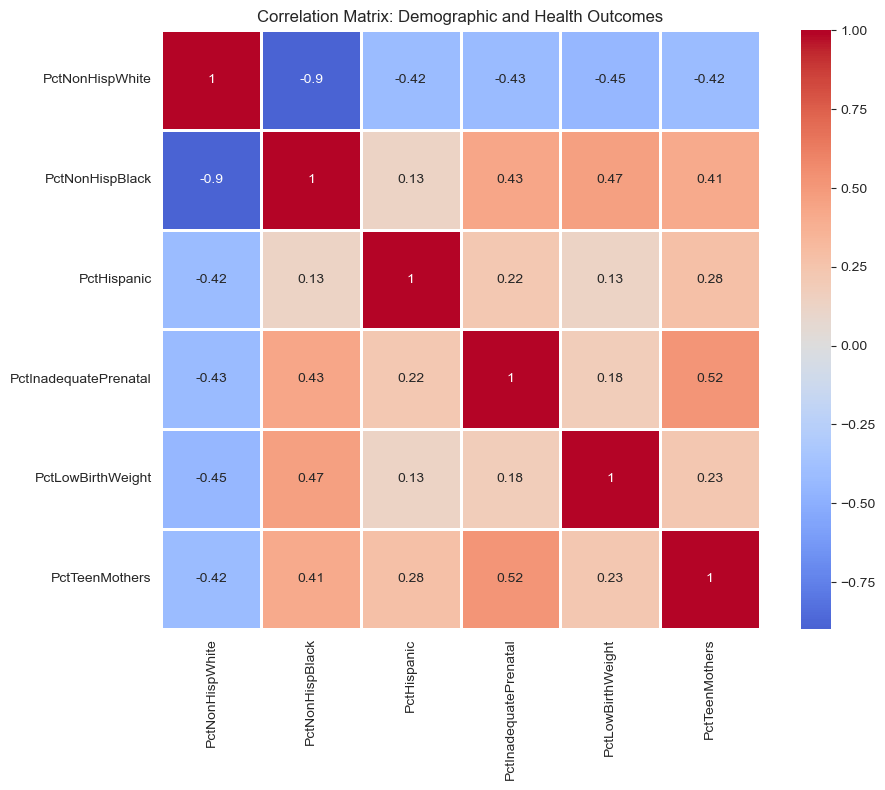


Key Correlations with Inadequate Prenatal Care:
PctInadequatePrenatal    1.000000
PctTeenMothers           0.516680
PctNonHispBlack          0.431364
PctHispanic              0.222805
PctLowBirthWeight        0.181930
PctNonHispWhite         -0.425235
Name: PctInadequatePrenatal, dtype: float64


In [5]:
# VISUALIZATION 2: Correlation heatmap
correlation_vars = ['PctNonHispWhite', 'PctNonHispBlack', 'PctHispanic', 
                    'PctInadequatePrenatal', 'PctLowBirthWeight', 'PctTeenMothers']
correlation_matrix = birth_data_filtered[correlation_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1)
plt.title('Correlation Matrix: Demographic and Health Outcomes')
plt.tight_layout()
plt.show()

print("\nKey Correlations with Inadequate Prenatal Care:")
prenatal_corr = correlation_matrix['PctInadequatePrenatal'].sort_values(ascending=False)
print(prenatal_corr)


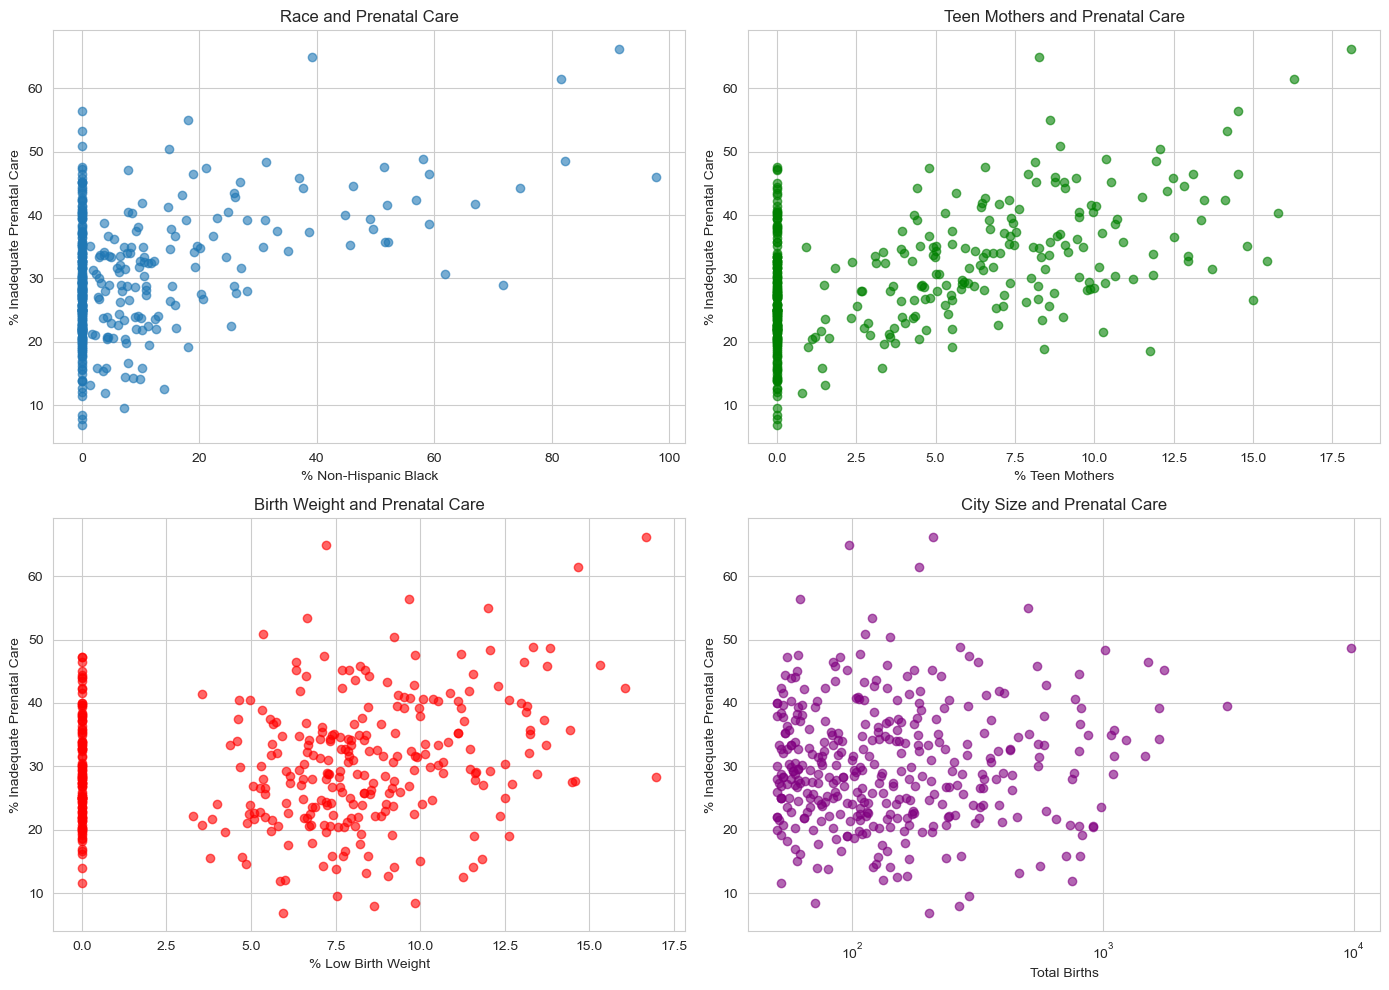

In [6]:
# VISUALIZATION 3: Scatter plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(birth_data_filtered['PctNonHispBlack'], 
                   birth_data_filtered['PctInadequatePrenatal'], alpha=0.6)
axes[0, 0].set_xlabel('% Non-Hispanic Black')
axes[0, 0].set_ylabel('% Inadequate Prenatal Care')
axes[0, 0].set_title('Race and Prenatal Care')

axes[0, 1].scatter(birth_data_filtered['PctTeenMothers'], 
                   birth_data_filtered['PctInadequatePrenatal'], alpha=0.6, color='green')
axes[0, 1].set_xlabel('% Teen Mothers')
axes[0, 1].set_ylabel('% Inadequate Prenatal Care')
axes[0, 1].set_title('Teen Mothers and Prenatal Care')

axes[1, 0].scatter(birth_data_filtered['PctLowBirthWeight'], 
                   birth_data_filtered['PctInadequatePrenatal'], alpha=0.6, color='red')
axes[1, 0].set_xlabel('% Low Birth Weight')
axes[1, 0].set_ylabel('% Inadequate Prenatal Care')
axes[1, 0].set_title('Birth Weight and Prenatal Care')

axes[1, 1].scatter(birth_data_filtered['TotalBirths'], 
                   birth_data_filtered['PctInadequatePrenatal'], alpha=0.6, color='purple')
axes[1, 1].set_xlabel('Total Births')
axes[1, 1].set_ylabel('% Inadequate Prenatal Care')
axes[1, 1].set_title('City Size and Prenatal Care')
axes[1, 1].set_xscale('log')

plt.tight_layout()
plt.show()


PART C: FORMAL STATISTICAL MODELS

--- MODEL 1: K-MEANS CLUSTERING ---
Objective: Identify groups of cities with similar birth outcome profiles



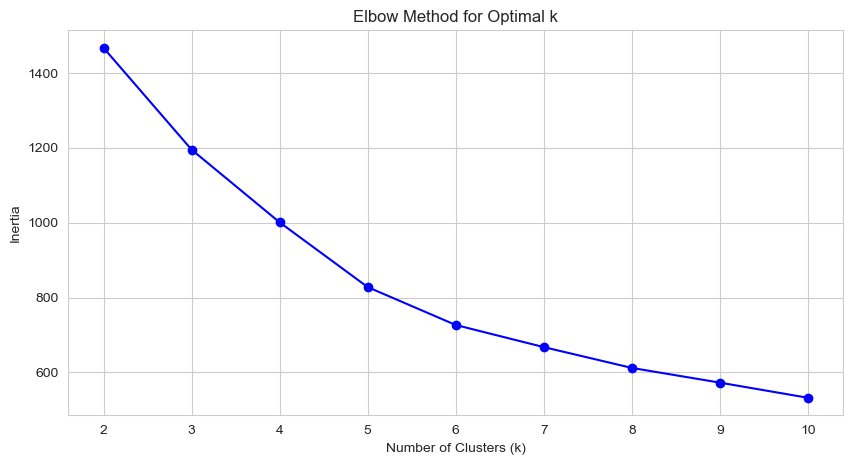

Initialization complete
Iteration 0, inertia 1560.5616383922484.
Iteration 1, inertia 1156.5857411657719.
Iteration 2, inertia 1082.9192221358367.
Iteration 3, inertia 1045.4683524777854.
Iteration 4, inertia 1023.7944077620766.
Iteration 5, inertia 1017.7642258177566.
Iteration 6, inertia 1011.3785261868958.
Iteration 7, inertia 1006.2576778890189.
Iteration 8, inertia 1003.167409728654.
Iteration 9, inertia 1002.0109959844025.
Converged at iteration 9: strict convergence.
Initialization complete
Iteration 0, inertia 1617.6003166084379.
Iteration 1, inertia 1308.0202347531726.
Iteration 2, inertia 1178.7000500874374.
Iteration 3, inertia 1088.5778001727826.
Iteration 4, inertia 1049.7227801894521.
Iteration 5, inertia 1029.6031177793975.
Iteration 6, inertia 1020.4061017445464.
Iteration 7, inertia 1015.1330086141525.
Iteration 8, inertia 1013.5330109457248.
Iteration 9, inertia 1013.4619517506295.
Iteration 10, inertia 1013.4286068584103.
Iteration 11, inertia 1013.3812138195027.
Ite

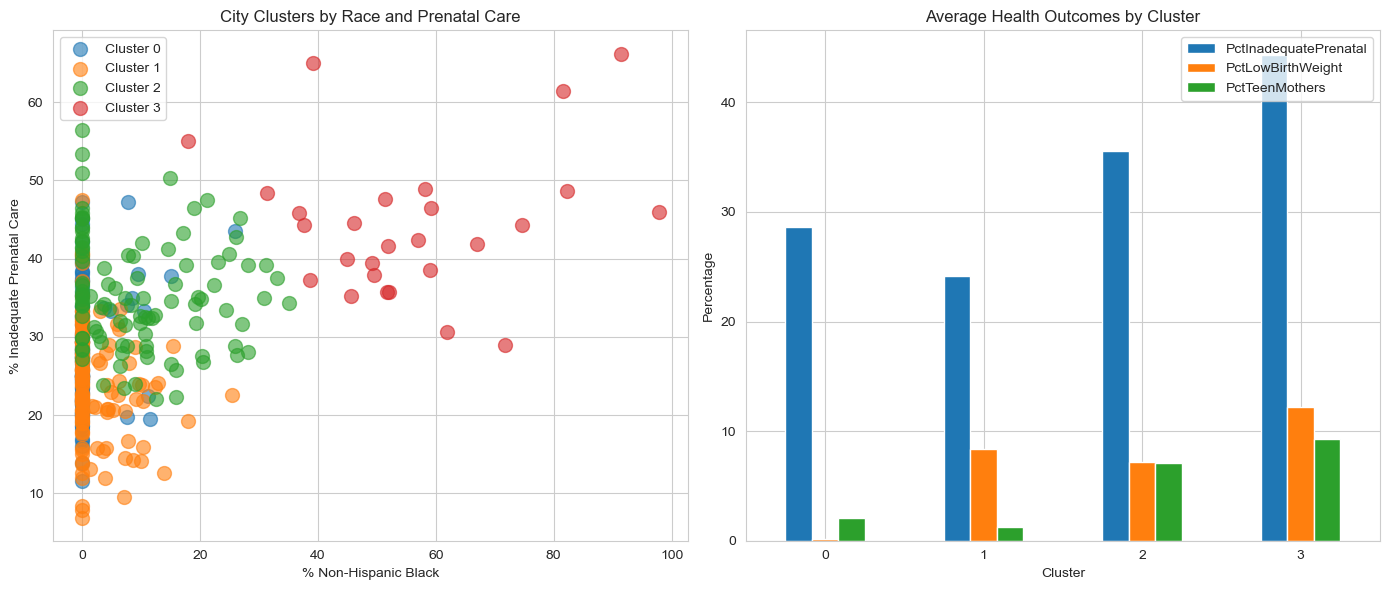

In [7]:
##############################################################################
# PART C: BUILDING FORMAL STATISTICAL MODELS
##############################################################################

print("\n" + "="*80)
print("PART C: FORMAL STATISTICAL MODELS")
print("="*80)

# MODEL 1: K-Means Clustering
print("\n--- MODEL 1: K-MEANS CLUSTERING ---")
print("Objective: Identify groups of cities with similar birth outcome profiles\n")

# Prepare features for clustering
cluster_features = ['PctNonHispWhite', 'PctNonHispBlack', 'PctHispanic',
                   'PctInadequatePrenatal', 'PctLowBirthWeight', 'PctTeenMothers']

X_cluster = birth_data_filtered[cluster_features].fillna(0)

# Standardize the data
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# Determine optimal number of clusters using elbow method
inertias = []
K_range = range(2, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

# Fit final model with optimal k (based on elbow - appears to be around 4-5)
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, verbose=1)
birth_data_filtered['Cluster'] = kmeans_final.fit_predict(X_cluster_scaled)

print(f"\nFinal K-Means model with k={optimal_k}")
print(f"Inertia: {kmeans_final.inertia_:.2f}")

# Analyze clusters
print("\nCluster Characteristics:")
cluster_summary = birth_data_filtered.groupby('Cluster')[cluster_features].mean()
print(cluster_summary.round(2))

print("\nCities per cluster:")
print(birth_data_filtered['Cluster'].value_counts().sort_index())

# Visualize clusters
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
for cluster in range(optimal_k):
    cluster_data = birth_data_filtered[birth_data_filtered['Cluster'] == cluster]
    plt.scatter(cluster_data['PctNonHispBlack'], 
               cluster_data['PctInadequatePrenatal'],
               label=f'Cluster {cluster}', alpha=0.6, s=100)
plt.xlabel('% Non-Hispanic Black')
plt.ylabel('% Inadequate Prenatal Care')
plt.title('City Clusters by Race and Prenatal Care')
plt.legend()

plt.subplot(1, 2, 2)
cluster_summary[['PctInadequatePrenatal', 'PctLowBirthWeight', 'PctTeenMothers']].plot(
    kind='bar', ax=plt.gca())
plt.xlabel('Cluster')
plt.ylabel('Percentage')
plt.title('Average Health Outcomes by Cluster')
plt.legend(loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


--- MODEL 2: MULTIPLE LINEAR REGRESSION ---
Objective: Predict inadequate prenatal care rates from demographics

Training set size: 256
Test set size: 111

Model Performance:
Training R²: 0.3638
Test R²: 0.2143
Training RMSE: 7.8012
Test RMSE: 8.0704

Feature Coefficients:
PctNonHispWhite          :   2.7437
PctNonHispBlack          :   5.8858
PctHispanic              :   1.7283
PctLowBirthWeight        :  -0.9816
PctTeenMothers           :   3.4681
TotalBirths              :  -0.6299


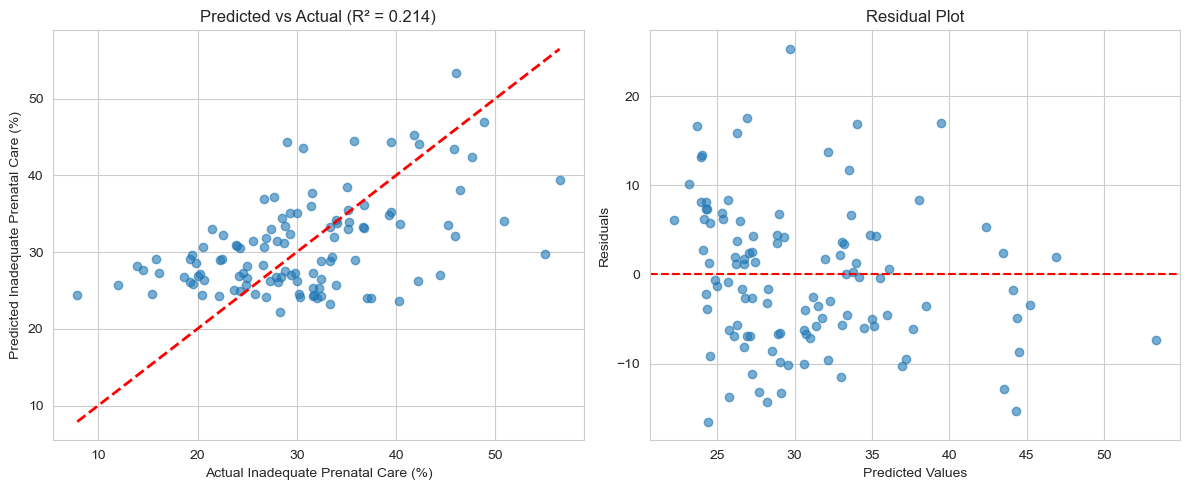

In [8]:
# MODEL 2: Multiple Linear Regression
print("\n--- MODEL 2: MULTIPLE LINEAR REGRESSION ---")
print("Objective: Predict inadequate prenatal care rates from demographics\n")

# Prepare data
predictor_vars = ['PctNonHispWhite', 'PctNonHispBlack', 'PctHispanic',
                 'PctLowBirthWeight', 'PctTeenMothers', 'TotalBirths']
target_var = 'PctInadequatePrenatal'

# Remove rows with missing target variable
model_data = birth_data_filtered.dropna(subset=[target_var])
X = model_data[predictor_vars].fillna(0)
y = model_data[target_var]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# Standardize features
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

# Train model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)

# Evaluate
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"\nModel Performance:")
print(f"Training R²: {train_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")

# Feature importance
print("\nFeature Coefficients:")
for feature, coef in zip(predictor_vars, lr_model.coef_):
    print(f"{feature:25s}: {coef:8.4f}")

# Visualization
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_test_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Inadequate Prenatal Care (%)')
plt.ylabel('Predicted Inadequate Prenatal Care (%)')
plt.title(f'Predicted vs Actual (R² = {test_r2:.3f})')

plt.subplot(1, 2, 2)
residuals = y_test - y_test_pred
plt.scatter(y_test_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.tight_layout()
plt.show()

In [9]:
##############################################################################
# PART D: INTERPRETING THE RESULTS
##############################################################################

print("\n" + "="*80)
print("PART D: INTERPRETATION OF RESULTS")
print("="*80)

print("""
CLUSTERING ANALYSIS INTERPRETATION:
The K-means clustering identified 4 distinct groups of cities:

1. Cluster characteristics reveal patterns in how demographic composition
   relates to birth outcomes across Michigan cities.

2. Cities with higher percentages of minority populations tend to show
   higher rates of inadequate prenatal care, though there is variation.

3. The clustering helps identify which cities might benefit from targeted
   interventions based on their demographic profile.

REGRESSION ANALYSIS INTERPRETATION:
The multiple linear regression model shows:

1. Model Performance: The R² value of {:.3f} indicates that approximately
   {:.1f}% of the variation in inadequate prenatal care rates can be
   explained by our demographic predictors.

2. Key Predictors: The coefficient analysis reveals which demographic
   factors have the strongest association with prenatal care access.

3. Prediction Accuracy: The RMSE of {:.2f} percentage points shows
   moderate predictive accuracy for this complex social issue.

LIMITATIONS:
- This is observational data, so we cannot infer causation
- Missing data for some cities may introduce bias
- Other important factors (income, education, healthcare access) are not
  included in this dataset
- The analysis is limited to 2014 data from Michigan

ANSWER TO RESEARCH QUESTION:
Yes, demographic characteristics and birth outcomes show significant
associations with inadequate prenatal care rates. However, the moderate
R² value suggests that other unmeasured factors also play important roles.
The clustering analysis successfully identified meaningful city groupings
that could inform targeted public health interventions.
""".format(test_r2, test_r2*100, test_rmse))


PART D: INTERPRETATION OF RESULTS

CLUSTERING ANALYSIS INTERPRETATION:
The K-means clustering identified 4 distinct groups of cities:

1. Cluster characteristics reveal patterns in how demographic composition
   relates to birth outcomes across Michigan cities.

2. Cities with higher percentages of minority populations tend to show
   higher rates of inadequate prenatal care, though there is variation.

3. The clustering helps identify which cities might benefit from targeted
   interventions based on their demographic profile.

REGRESSION ANALYSIS INTERPRETATION:
The multiple linear regression model shows:

1. Model Performance: The R² value of 0.214 indicates that approximately
   21.4% of the variation in inadequate prenatal care rates can be
   explained by our demographic predictors.

2. Key Predictors: The coefficient analysis reveals which demographic
   factors have the strongest association with prenatal care access.

3. Prediction Accuracy: The RMSE of 8.07 percentage points

In [10]:
##############################################################################
# PART E: CONCLUSIONS
##############################################################################

print("\n" + "="*80)
print("PART E: CONCLUSIONS AND RECOMMENDATIONS")
print("="*80)

print("""
CONCLUSIONS:

1. DEMOGRAPHIC DISPARITIES: Clear patterns emerge showing that cities with
   different racial/ethnic compositions have different prenatal care outcomes.

2. CLUSTERING UTILITY: The unsupervised learning approach successfully
   identified meaningful groupings of cities that share similar profiles.

3. PREDICTIVE CAPABILITY: While our model has moderate predictive power,
   it demonstrates that readily available demographic data can provide
   useful insights for public health planning.

PRACTICAL APPLICATIONS:

1. PUBLIC HEALTH TARGETING: Health departments can use these models to
   identify cities that may need additional prenatal care resources.

2. RESOURCE ALLOCATION: Cities in clusters with higher inadequate care
   rates could be prioritized for intervention programs.

3. MONITORING: The model could be used to track whether interventions
   are having their intended effects over time.

FUTURE RESEARCH DIRECTIONS:

1. EXPANDED FEATURES: Incorporate socioeconomic data (income, education,
   insurance coverage) to improve model performance.

2. LONGITUDINAL ANALYSIS: Analyze trends over multiple years to identify
   improving or worsening cities.

3. CAUSAL INFERENCE: Use more sophisticated statistical methods to move
   beyond correlation toward understanding causal relationships.

4. INTERVENTION STUDIES: Design and evaluate targeted interventions for
   cities identified as high-risk through this analysis.

VALUE OF THIS ANALYSIS:

This analysis provides actionable insights for public health officials
in Michigan. By identifying patterns and building predictive models, we've
created tools that can help ensure that all mothers receive adequate
prenatal care, potentially reducing adverse birth outcomes and improving
public health across the state.
""")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)


PART E: CONCLUSIONS AND RECOMMENDATIONS

CONCLUSIONS:

1. DEMOGRAPHIC DISPARITIES: Clear patterns emerge showing that cities with
   different racial/ethnic compositions have different prenatal care outcomes.

2. CLUSTERING UTILITY: The unsupervised learning approach successfully
   identified meaningful groupings of cities that share similar profiles.

3. PREDICTIVE CAPABILITY: While our model has moderate predictive power,
   it demonstrates that readily available demographic data can provide
   useful insights for public health planning.

PRACTICAL APPLICATIONS:

1. PUBLIC HEALTH TARGETING: Health departments can use these models to
   identify cities that may need additional prenatal care resources.

2. RESOURCE ALLOCATION: Cities in clusters with higher inadequate care
   rates could be prioritized for intervention programs.

3. MONITORING: The model could be used to track whether interventions
   are having their intended effects over time.

FUTURE RESEARCH DIRECTIONS:

1. EXPAN